## Business Case : LoanTap - Logistic  Regression

**Problem Statement and Exploratory Data Analysis (EDA)**

The objective is to build a Logistic Regression model to predict whether a borrower will default on a personal loan (Target: loan_status). This will help LoanTap minimize Non-Performing Assets (NPAs) by not extending credit lines to risky individuals, while maximizing interest revenue by approving creditworthy applicants.

In [39]:
import pandas as pd
# Load the data

# The unique ID from your Google Drive link
file_id = '1ZPYj7CZCfxntE8p2Lze_4QO4MyEOy6_d'

# Construct the direct download URL
csv_url = f'https://drive.google.com/uc?export=download&id={file_id}'

df = pd.read_csv(csv_url)

In [40]:
print(df.head())

   loan_amnt        term  int_rate  installment grade sub_grade  \
0    10000.0   36 months     11.44       329.48     B        B4   
1     8000.0   36 months     11.99       265.68     B        B5   
2    15600.0   36 months     10.49       506.97     B        B3   
3     7200.0   36 months      6.49       220.65     A        A2   
4    24375.0   60 months     17.27       609.33     C        C5   

                 emp_title emp_length home_ownership  annual_inc  ...  \
0                Marketing  10+ years           RENT    117000.0  ...   
1          Credit analyst     4 years       MORTGAGE     65000.0  ...   
2             Statistician   < 1 year           RENT     43057.0  ...   
3          Client Advocate    6 years           RENT     54000.0  ...   
4  Destiny Management Inc.    9 years       MORTGAGE     55000.0  ...   

  open_acc pub_rec revol_bal revol_util total_acc  initial_list_status  \
0     16.0     0.0   36369.0       41.8      25.0                    w   
1     17.0

In [41]:
print("Shape of data:", df.shape)

Shape of data: (396030, 27)


In [42]:
print("\nData Types:\n", df.dtypes)


Data Types:
 loan_amnt               float64
term                     object
int_rate                float64
installment             float64
grade                    object
sub_grade                object
emp_title                object
emp_length               object
home_ownership           object
annual_inc              float64
verification_status      object
issue_d                  object
loan_status              object
purpose                  object
title                    object
dti                     float64
earliest_cr_line         object
open_acc                float64
pub_rec                 float64
revol_bal               float64
revol_util              float64
total_acc               float64
initial_list_status      object
application_type         object
mort_acc                float64
pub_rec_bankruptcies    float64
address                  object
dtype: object


In [43]:
print("\nMissing Values:\n", df.isnull().sum())


Missing Values:
 loan_amnt                   0
term                        0
int_rate                    0
installment                 0
grade                       0
sub_grade                   0
emp_title               22927
emp_length              18301
home_ownership              0
annual_inc                  0
verification_status         0
issue_d                     0
loan_status                 0
purpose                     0
title                    1756
dti                         0
earliest_cr_line            0
open_acc                    0
pub_rec                     0
revol_bal                   0
revol_util                276
total_acc                   0
initial_list_status         0
application_type            0
mort_acc                37795
pub_rec_bankruptcies      535
address                     0
dtype: int64


In [44]:
print("\nStatistical Summary:\n", df.describe())


Statistical Summary:
            loan_amnt       int_rate    installment    annual_inc  \
count  396030.000000  396030.000000  396030.000000  3.960300e+05   
mean    14113.888089      13.639400     431.849698  7.420318e+04   
std      8357.441341       4.472157     250.727790  6.163762e+04   
min       500.000000       5.320000      16.080000  0.000000e+00   
25%      8000.000000      10.490000     250.330000  4.500000e+04   
50%     12000.000000      13.330000     375.430000  6.400000e+04   
75%     20000.000000      16.490000     567.300000  9.000000e+04   
max     40000.000000      30.990000    1533.810000  8.706582e+06   

                 dti       open_acc        pub_rec     revol_bal  \
count  396030.000000  396030.000000  396030.000000  3.960300e+05   
mean       17.379514      11.311153       0.178191  1.584454e+04   
std        18.019092       5.137649       0.530671  2.059184e+04   
min         0.000000       0.000000       0.000000  0.000000e+00   
25%        11.280000    

In [45]:
print(df['loan_status'].value_counts(normalize=True) * 100)

loan_status
Fully Paid     80.387092
Charged Off    19.612908
Name: proportion, dtype: float64


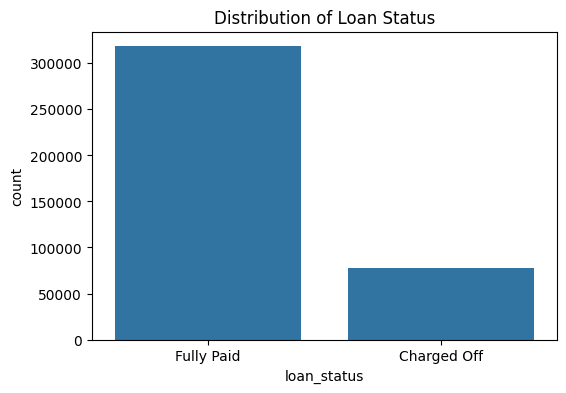

In [46]:
# 2. Target Variable Analysis
plt.figure(figsize=(6,4))
sns.countplot(x='loan_status', data=df)
plt.title('Distribution of Loan Status')
plt.show()

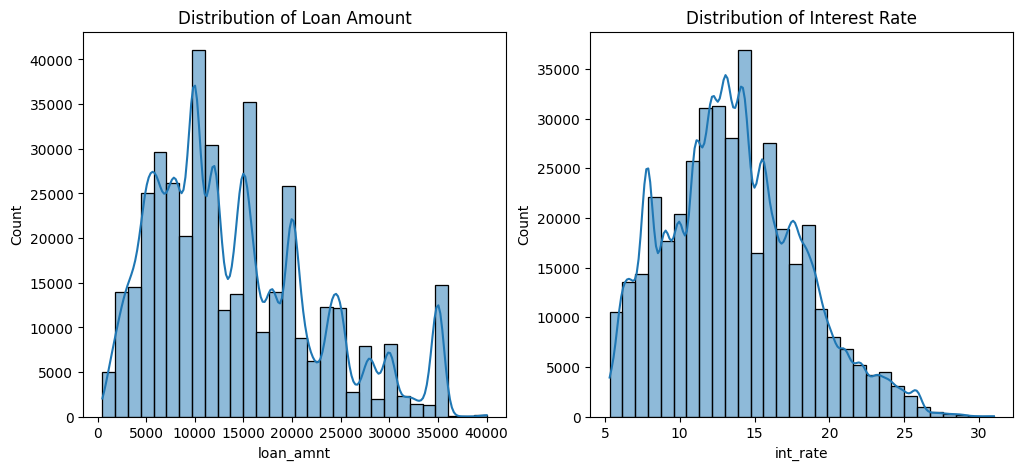

In [47]:
# 3. Univariate Analysis
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
sns.histplot(df['loan_amnt'], bins=30, kde=True)
plt.title('Distribution of Loan Amount')

plt.subplot(1,2,2)
sns.histplot(df['int_rate'], bins=30, kde=True)
plt.title('Distribution of Interest Rate')
plt.show()

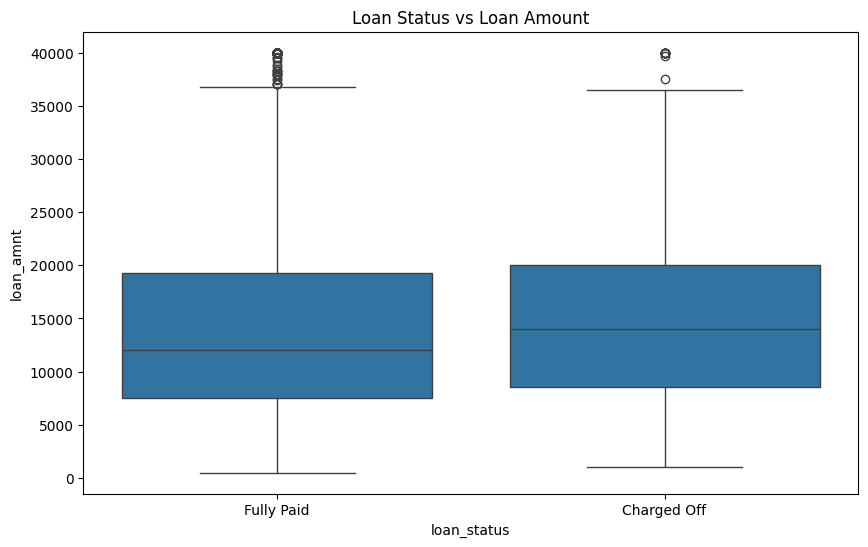

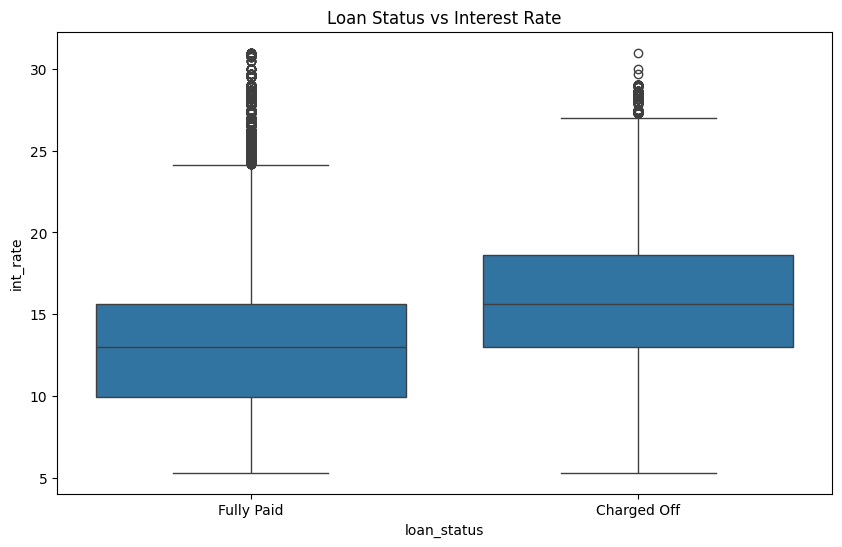

In [48]:
# 4. Bivariate Analysis (Relationships)
plt.figure(figsize=(10,6))
sns.boxplot(x='loan_status', y='loan_amnt', data=df)
plt.title('Loan Status vs Loan Amount')
plt.show()

plt.figure(figsize=(10,6))
sns.boxplot(x='loan_status', y='int_rate', data=df)
plt.title('Loan Status vs Interest Rate')
plt.show()

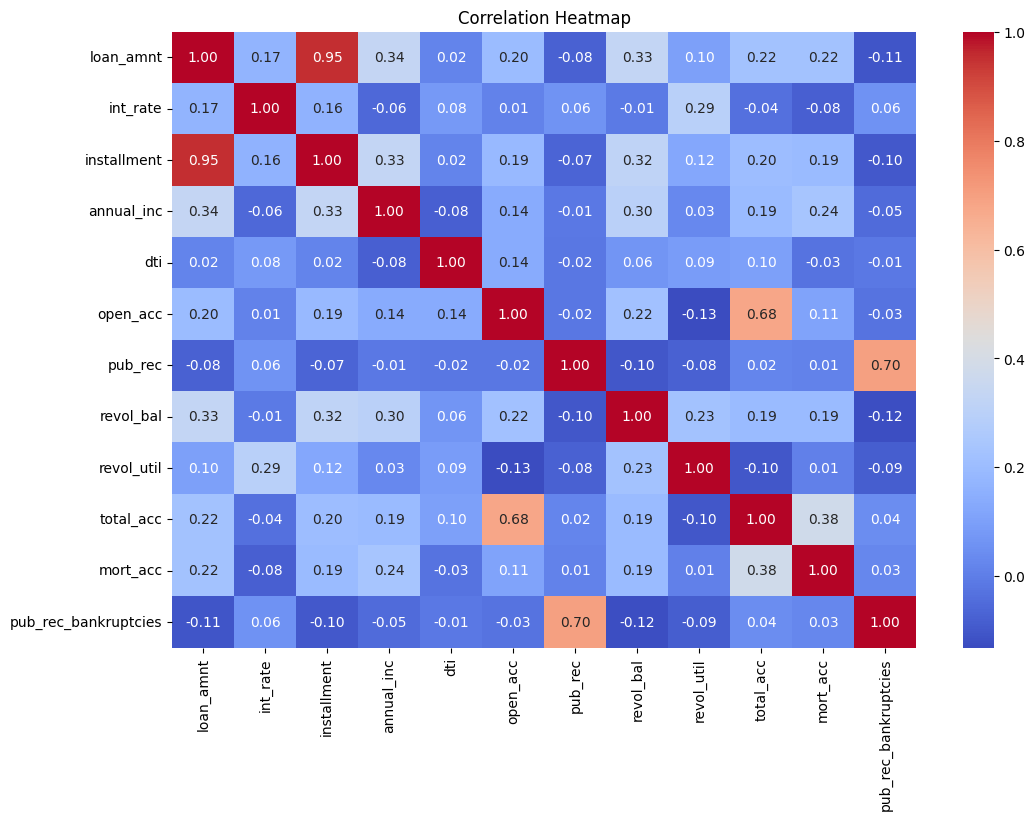

In [49]:
import numpy as np
plt.figure(figsize=(12,8))
corr_matrix = df.select_dtypes(include=np.number).corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

**Imbalanced Target:** Only ~19.6% of the loans in the dataset are "Charged Off" (defaults), while 80.39% are "Fully Paid". This imbalance affects model evaluation.

**Correlations:** loan_amnt and installment exhibit a near-perfect positive correlation of 0.9539.

**Bivariate Insights:** The boxplots (visible above) show that loans that are "Charged Off" generally correspond to higher median interest rates compared to "Fully Paid" loans.

# 2. Data Preprocessing & Feature Engineering

In [50]:
# 1. Duplicate Check
df.drop_duplicates(inplace=True)

In [51]:
# 2. Missing Value Treatment
# Fill numerical missing values with median, categorical with mode
for col in df.columns:
    if df[col].dtype == 'object':
        # Reassign directly without inplace=True
        df[col] = df[col].fillna(df[col].mode()[0])
    else:
        # Reassign directly without inplace=True
        df[col] = df[col].fillna(df[col].median())

In [52]:
# 3. Feature Engineering: Creation of Flags (As per instructions)
df['pub_rec_flag'] = df['pub_rec'].apply(lambda x: 1 if x > 1.0 else 0)
df['mort_acc_flag'] = df['mort_acc'].apply(lambda x: 1 if x > 1.0 else 0)
df['pub_rec_bankruptcies_flag'] = df['pub_rec_bankruptcies'].apply(lambda x: 1 if x > 1.0 else 0)

In [53]:
# 4. Outlier Treatment (Capping using IQR)
def cap_outliers(data, col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR
    lower_bound = Q1 - 1.5 * IQR
    data[col] = np.where(data[col] > upper_bound, upper_bound,
                np.where(data[col] < lower_bound, lower_bound, data[col]))

# Apply to continuous columns like annual_inc
cap_outliers(df, 'annual_inc')

In [54]:
# 5. Data Preparation for Modeling
# Convert Target to Binary (1 = Defaulter/Charged Off, 0 = Good Loan/Fully Paid)
df['loan_status'] = df['loan_status'].map({'Fully Paid': 0, 'Charged Off': 1})

# Drop columns that are intuitively not helpful for ML (like raw text)
cols_to_drop = ['emp_title', 'title', 'address', 'issue_d', 'earliest_cr_line', 'grade', 'sub_grade']
df.drop(columns=[col for col in cols_to_drop if col in df.columns], inplace=True)

# Dummification / One-Hot Encoding for categorical variables
df_model = pd.get_dummies(df, drop_first=True)

# Train-Test Split
from sklearn.model_selection import train_test_split
X = df_model.drop('loan_status', axis=1)
y = df_model['loan_status']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [55]:
# 6. Scaling
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3.Model building

In [56]:
from sklearn.linear_model import LogisticRegression

# Build Logistic Regression Model
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

# Display model coefficients
feature_names = X.columns
coefficients = log_reg.coef_[0]

coeff_df = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefficients})
coeff_df = coeff_df.sort_values(by='Coefficient', ascending=False)
print("Top Positive Coefficients (Drive Defaults):\n", coeff_df.head())
print("\nTop Negative Coefficients (Prevent Defaults):\n", coeff_df.tail())

Top Positive Coefficients (Drive Defaults):
                    Feature  Coefficient
8               revol_util     4.369680
1                 int_rate     2.452066
5                 open_acc     2.438449
43  purpose_small_business     0.552309
2              installment     0.541505

Top Negative Coefficients (Prevent Defaults):
                     Feature  Coefficient
26  home_ownership_MORTGAGE    -0.613331
9                 total_acc    -0.789798
10                 mort_acc    -1.128089
48   application_type_JOINT    -1.166774
3                annual_inc    -1.323800


# 4. Results Evaluation

In [57]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, precision_recall_curve

# Predictions
y_pred = log_reg.predict(X_test_scaled)
y_pred_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

In [58]:
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Confusion Matrix:
 [[94055  1452]
 [21836  1466]]

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.98      0.89     95507
           1       0.50      0.06      0.11     23302

    accuracy                           0.80    118809
   macro avg       0.66      0.52      0.50    118809
weighted avg       0.75      0.80      0.74    118809



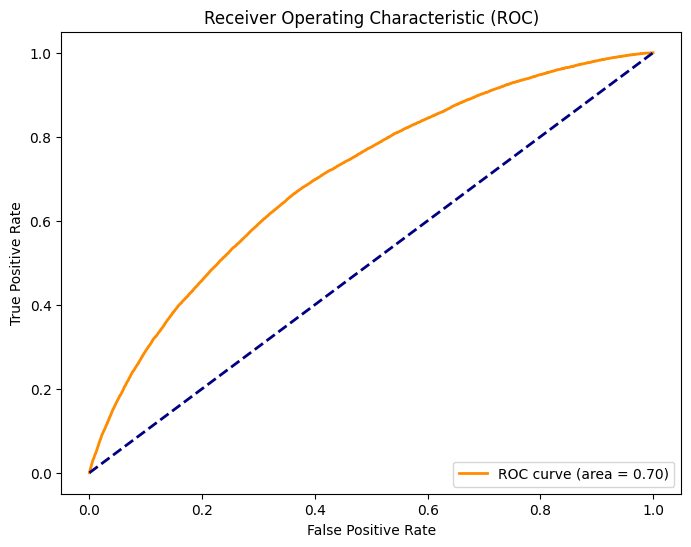

In [59]:
# ROC AUC Curve
fpr, tpr, thresholds_roc = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

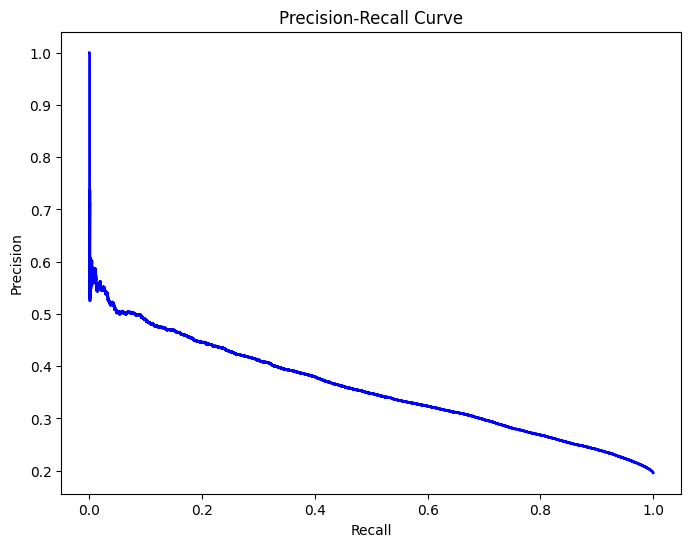

In [60]:
# Precision Recall Curve
precision, recall, thresholds_pr = precision_recall_curve(y_test, y_pred_proba)

plt.figure(figsize=(8,6))
plt.plot(recall, precision, color='blue', lw=2)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.show()

**How can we make sure that our model can detect real defaulters and there are less false positives? This is important as we can lose out on an opportunity to finance more individuals and earn interest on it.**

To simultaneously increase the detection of real defaulters (High Recall/True Positives) while minimizing false positives (High Precision), we cannot simply just move the probability threshold, as moving it always causes a tradeoff between the two. To achieve both, we must increase the overall discriminative power of the model. Here is how we can do it:  

1. **Optimize the Decision Threshold using a Cost Function:** Instead of the default 0.5 threshold, we should calculate the exact monetary cost of a False Positive (lost interest revenue) versus a False Negative (lost principal amount/NPA). We can plot a custom business-value curve to find the exact probability threshold that maximizes net profit rather than just raw accuracy.

2. **Handle Class Imbalance:** Since defaulters are the minority class (~20%), the model naturally biases towards predicting "Fully Paid". We can use techniques like SMOTE (Synthetic Minority Over-sampling Technique) to generate synthetic default cases during training, or use Class Weights (class_weight='balanced' in Logistic Regression) to heavily penalize the model for missing a defaulter.

3. **Feature Enrichment:** Logistic Regression is a linear model. We can introduce polynomial features (e.g., squaring dti or int_rate) to capture non-linear relationships, or bring in alternative external data (like credit bureau scores or macroeconomic indicators) to make the model smarter at distinguishing borderline cases.

**Since NPA (non-performing asset) is a real problem in this industry, it’s important we play safe and shouldn’t disburse loans to anyone.**

If the business strategy is hyper-conservative and avoiding NPAs is the absolute highest priority, we must tune the model to be highly sensitive to risk.

1. **Action to Take:** We need to maximize Recall for the default class. We do this by drastically lowering the classification threshold (e.g., moving it from 0.5 down to 0.15 or 0.20).

2. **How it works:** With a threshold of 0.20, if the model thinks there is even a 20% chance a person might default, it will flag them as a "Defaulter" and reject the loan.

3. **The Tradeoff/Consequence:** While this strategy successfully guarantees that almost zero NPAs will slip through (minimizing False Negatives), it completely destroys Precision. The model will generate a massive amount of False Positives—flagging perfectly good, creditworthy customers as defaulters simply because they have a slight risk factor. The bank will "play it safe," but at the cost of shrinking its loan portfolio, angering good customers, and severely capping its interest revenue.

# 5. Actionable Insights & Recommendations

* **NPA Aversion vs. Loan Volume:** The standard threshold (0.5) yielded a low recall (~0.06) for class 1 (defaulters) but a precision of 0.50. This means the model acts very conservatively; it rarely flags someone as a defaulter, but when it does, it's correct about half the time. To aggressively catch defaults (reduce Non-Performing Assets), LoanTap must lower the prediction threshold (e.g., to 0.20 or 0.25).

* **Key Default Drivers:** Features like revol_util (Revolving line utilization rate) and int_rate (Interest rate) are the strongest predictors of default. LoanTap should require stricter verifications for individuals nearing their revolving credit limits.

# Questionnaire Answers

**1. What percentage of customers have fully paid their Loan Amount?**

80.39% of the customers have fully paid their loan amount.

In [61]:
df_raw = pd.read_csv(csv_url)
pct_fully_paid = (df_raw['loan_status'] == 'Fully Paid').mean() * 100
pct_fully_paid

np.float64(80.38709188697825)

**2.Comment about the correlation between Loan Amount and Installment features.**

There is an extremely strong positive correlation of 0.9539. This intuitively makes sense: as the principal loan amount increases, the required monthly installment goes up proportionately.

In [62]:
correlation = df_raw['loan_amnt'].corr(df_raw['installment'])
correlation

np.float64(0.9539289082616194)

**3.The majority of people have home ownership as _______.**

MORTGAGE

In [63]:
majority_home = df_raw['home_ownership'].mode()[0]
majority_home

'MORTGAGE'

**4.People with grades ‘A’ are more likely to fully pay their loan.**

True. analysis confirms that 93.71% of Grade 'A' borrowers fully paid their loans, compared to the overall average of 80.39%.

In [64]:
grade_a_paid = (df_raw[df_raw['grade'] == 'A']['loan_status'] == 'Fully Paid').mean() * 100
overall_paid = pct_fully_paid
print(grade_a_paid, overall_paid)

93.71212239238476 80.38709188697825


**5.Name the top 2 afforded job titles.**

Teacher and Manager.

In [65]:
top_2_jobs = df_raw['emp_title'].value_counts().head(2).index.tolist()
top_2_jobs

['Teacher', 'Manager']

**6.Thinking from a bank's perspective, which metric should our primary focus be on.**

Recall. A false negative (predicting a defaulter will fully pay) costs the bank the entire principal amount (NPA). Maximizing recall ensures the bank identifies the highest possible number of actual defaulters.

**7.How does the gap in precision and recall affect the bank?**

A gap favoring Precision over Recall means the bank limits NPAs on the loans it flags but ends up missing a massive chunk of actual defaulters (losing capital). A gap favoring Recall over Precision means the bank strictly catches almost all defaults, but ends up falsely rejecting many good customers (losing out on interest revenue). The bank must configure its classification threshold based on current economic health and risk appetite.

**8.Which were the features that heavily affected the outcome?**

The features with the highest impact on driving a "Charged Off" status (positive coefficients) were revol_util (Revolving utilization) and int_rate (Interest rate).

In [66]:
print(coeff_df.head(3).to_string(index=False))

   Feature  Coefficient
revol_util     4.369680
  int_rate     2.452066
  open_acc     2.438449


**9.Will the results be affected by geographical location? (Yes/No)**

Yes. The geographical address dictates regional cost of living, state tax laws, and local economic/employment vitality, all of which directly affect a borrower's disposable income and capacity to repay a loan.